# 04 · Face verification (Phase 4)

**The KYC question:** does the selfie show the same person as the photo on the ID document? A face model turns
each face into an *embedding* (a list of numbers); two photos of the same person should give similar embeddings.
The similarity score is compared with a threshold: at or above it, the faces are accepted as the same person.

**Two models.**
- **A. Production path (pretrained):** OpenCV's **YuNet** face detector and **SFace** face recognizer
  (`cv2.FaceDetectorYN`, `cv2.FaceRecognizerSF`), ONNX files from the official `opencv_zoo` repository (YuNet:
  MIT licence, SFace: Apache 2.0). YuNet finds the face and 5 landmarks; SFace aligns the face to 112x112 and
  embeds it. Score = cosine similarity of the two embeddings.
- **B. Deep-learning showcase:** a **Keras Siamese network**. One shared embedding network (frozen ImageNet
  MobileNetV2 plus a trained head) is applied to both faces, and a small head outputs P(same person). It is
  trained on LFW training pairs.

**Threshold rule.** In KYC the costly error is a **false accept**: an impostor passes as the ID holder. Every
threshold is therefore the one with the highest true-accept rate among those with a false-accept rate
(**FAR**) of at most 1 %. It is chosen on LFW **train** pairs (model A) or on held-out validation pairs taken
from them (model B). The 1,000 LFW **test** pairs are used once, at the end, for both models.

**Data.** LFW pairs as loaded by scikit-learn (`fetch_lfw_pairs`, colour, 125x94 px crops) from `data/raw/lfw`:
LFW's development split, 2,200 train and 1,000 test pairs, half of them same-person pairs. The last section is a
**sanity check on ID photos**: synthetic, clearly not a benchmark.

Code: `src/ekyc/face.py` (`detect_and_align`, `embed`, `compare`, LFW helpers, Siamese network),
`src/ekyc/evaluation.py` (`threshold_at_far`, `equal_error_rate`, `verification_report`). Tests: `tests/test_face.py`.

In [1]:
import hashlib
import json
import os
import re
import subprocess
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # hide TensorFlow's C++ info messages

import cv2
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.datasets import fetch_lfw_pairs
from sklearn.metrics import roc_curve

from ekyc import config, evaluation, face, models

keras.utils.set_random_seed(config.SEED)
ROOT = config.PROJECT_ROOT
SMOKE_DIR = None  # None in the real run
REPORT_DIR = Path(SMOKE_DIR) / "reports" if SMOKE_DIR else config.REPORTS_DIR / "phase4"
MODEL_DIR = Path(SMOKE_DIR) / "models" if SMOKE_DIR else ROOT / "models"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MAX_FAR = config.FACE_MAX_FAR  # 1 %: every threshold allows at most this share of impostors through
SIAMESE = {"image_size": 128, "embedding_dim": 128, "dropout": 0.2, "batch_size": 32, "learning_rate": 1e-3,
           "max_epochs": 2 if SMOKE_DIR else 40, "patience": 6, "reduce_lr_patience": 2, "holdout": 0.15}
N_ID_DOCS = 40 if SMOKE_DIR else None  # ID sanity check: None = all 1,000 genuine templates

SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"  # validated colour-blind-safe order; always with a legend
MODEL_COLOR = {"SFace (production)": BLUE, "Siamese (showcase)": ORANGE}
SAME, DIFFERENT = AQUA, MUTED  # same-person pairs vs different-people pairs, in every histogram


def style(ax, title):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.xaxis.label.set_color(INK_2)
    ax.yaxis.label.set_color(INK_2)


def peak_memory_gb():
    """Peak physical memory of this notebook process (includes GPU buffers, which share RAM on Apple Silicon)."""
    out = subprocess.run(["footprint", "-p", str(os.getpid())], capture_output=True, text=True).stdout
    value, unit = re.search(r"phys_footprint_peak:\s*([\d.]+)\s*(KB|MB|GB)", out).groups()
    return float(value) / {"KB": 1024 ** 2, "MB": 1024, "GB": 1}[unit]


def swap_used_gb():
    out = subprocess.run(["sysctl", "-n", "vm.swapusage"], capture_output=True, text=True).stdout
    return float(re.search(r"used = ([\d.]+)M", out).group(1)) / 1024


notebook_start = time.perf_counter()
print(f"OpenCV {cv2.__version__} | TensorFlow {tf.__version__} | Keras {keras.__version__} | "
      f"GPU: {tf.config.list_physical_devices('GPU')}")
print(f"max FAR {MAX_FAR:.0%} | Siamese {SIAMESE}")
print(f"swap in use at start: {swap_used_gb():.1f} GB" + (" | SMOKE TEST" if SMOKE_DIR else ""))

OpenCV 5.0.0 | TensorFlow 2.18.1 | Keras 3.15.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
max FAR 1% | Siamese {'image_size': 128, 'embedding_dim': 128, 'dropout': 0.2, 'batch_size': 32, 'learning_rate': 0.001, 'max_epochs': 40, 'patience': 6, 'reduce_lr_patience': 2, 'holdout': 0.15}
swap in use at start: 13.5 GB


<!-- id: setup -->
**Setup.** OpenCV 5.0.0 (already in the environment since Phase 1, so nothing was installed for this phase),
TensorFlow 2.18.1 with the Metal GPU, Keras 3.15.1. All settings are in this cell: the FAR target (1 %), and the
Siamese network's size and training rules. These are the same stability rules as Phases 3A and 3B: frozen
BatchNormalization, gradient clipping, `TerminateOnNaN`, and a checkpoint on the best validation score.

## 1 · LFW pairs

In [2]:
def load_lfw(subset):
    """LFW pairs from the local copy (never downloaded here) as uint8, plus the two names of every pair."""
    lfw = fetch_lfw_pairs(subset=subset, color=True, resize=1.0, data_home=config.LFW_DIR, download_if_missing=False)
    pairs = np.clip(np.rint(lfw.pairs * 255), 0, 255).astype(np.uint8)  # sklearn gives floats 0-1
    names = face.lfw_pair_names(subset)
    assert (names["same"].to_numpy() == lfw.target).all(), "names and pairs are not in the same order"
    return pairs, lfw.target.astype(int), names


lfw = {subset: load_lfw(subset) for subset in ("train", "test")}
if SMOKE_DIR:  # a few pairs of each kind
    for subset, n in (("train", 60), ("test", 40)):
        pairs, y, names = lfw[subset]
        keep = np.r_[np.flatnonzero(y == 1)[:n], np.flatnonzero(y == 0)[:n]]
        lfw[subset] = (pairs[keep], y[keep], names.iloc[keep].reset_index(drop=True))
(train_pairs, y_train, train_names), (test_pairs, y_test, test_names) = lfw["train"], lfw["test"]
people = {s: set(n["name_a"]) | set(n["name_b"]) for s, (_, _, n) in lfw.items()}
display(pd.DataFrame({s: {"pairs": len(y), "same person": int(y.sum()), "different people": int((y == 0).sum()),
                          "people": len(people[s]), "image size": f"{p.shape[2]}x{p.shape[3]}"}
                      for s, (p, y, _) in lfw.items()}).T)
print(f"people in both train and test pairs: {len(people['train'] & people['test'])}")
print(f"memory: train pairs {train_pairs.nbytes / 1e6:.0f} MB, test pairs {test_pairs.nbytes / 1e6:.0f} MB (uint8)")

,pairs,same person,different people,people,image size
train,2200,1100,1100,2132,125x94
test,1000,500,500,963,125x94


people in both train and test pairs: 0
memory: train pairs 155 MB, test pairs 70 MB (uint8)


<!-- id: lfw -->
**LFW pairs.** The development split of Labeled Faces in the Wild:
- **train:** 2,200 pairs (1,100 same person, 1,100 different people) of 2,132 people;
- **test:** 1,000 pairs (500 / 500) of 963 people.

No person appears in both, so the test measures performance on new faces. The images are 125x94 colour crops,
loaded from the local copy (`download_if_missing=False`). The names of each pair are read from LFW's own pair
files, and the code checks that they line up with scikit-learn's pairs (same order, same labels).

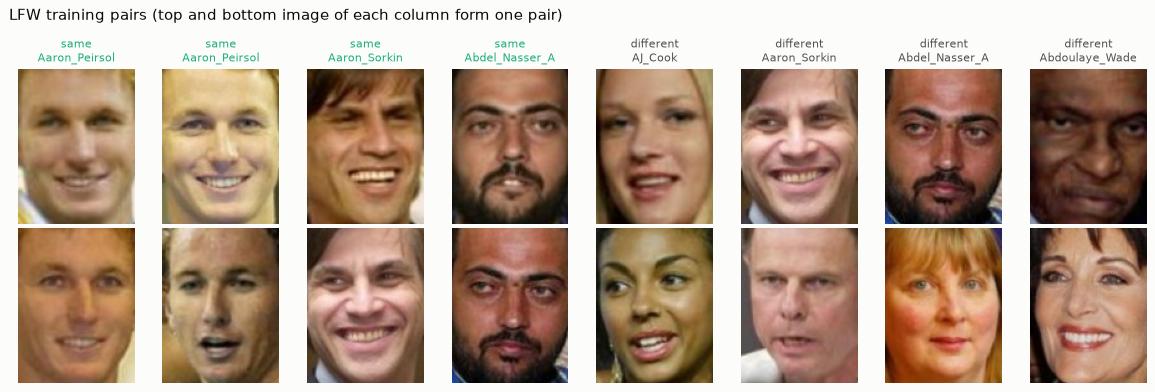

In [3]:
# 4 same-person and 4 different-people training pairs (each column is one pair)
fig, axes = plt.subplots(2, 8, figsize=(13, 4.4), dpi=90, facecolor=SURFACE)
examples = np.r_[np.flatnonzero(y_train == 1)[:4], np.flatnonzero(y_train == 0)[:4]]
for column, i in enumerate(examples):
    for row in range(2):
        axes[row, column].imshow(train_pairs[i, row])
        axes[row, column].axis("off")
    axes[0, column].set_title(("same" if y_train[i] else "different") + f"\n{train_names.loc[i, 'name_a'][:14]}",
                              fontsize=9, color=SAME if y_train[i] else INK_2)
fig.suptitle("LFW training pairs (top and bottom image of each column form one pair)", x=0.01, ha="left", color=INK)
fig.tight_layout()
fig.savefig(REPORT_DIR / "face_lfw_examples.png", dpi=120, facecolor=SURFACE, bbox_inches="tight")
plt.show()

<!-- id: lfw_examples -->
**What the pairs look like.** Each column is one pair. Same-person pairs (green titles) show one celebrity in two
different photos: other lighting, pose, expression, age. Different-people pairs are random strangers. The crops
are tight: forehead and chin are often cut off.

## 2 · Production path: YuNet + SFace

In [4]:
detector, recognizer = face.load_face_models()
SOURCES = {"detector": ("YuNet", config.YUNET_ONNX, "MIT", "face_detection_yunet"),
           "recognizer": ("SFace", config.SFACE_ONNX, "Apache-2.0", "face_recognition_sface")}
model_files = pd.DataFrame({role: {"model": name, "file": path.name, "MB": path.stat().st_size / 1e6,
                                   "sha256": hashlib.sha256(path.read_bytes()).hexdigest(), "license": licence,
                                   "source": f"github.com/opencv/opencv_zoo/tree/main/models/{folder}"}
                            for role, (name, path, licence, folder) in SOURCES.items()}).T
display(model_files.drop(columns="sha256").round(2))
print("detector settings:", face.DETECTOR_SETTINGS)

start = time.perf_counter()
flat = train_pairs.reshape(-1, *train_pairs.shape[2:])  # pair i -> images 2i and 2i+1
train_embeddings, train_detect = face.embed_images(flat, detector, recognizer)
seconds = time.perf_counter() - start
print(f"\n{len(flat):,} training images: face found in {train_detect['found'].sum():,} "
      f"({train_detect['found'].mean():.2%}); more than one face in {(train_detect['faces'] > 1).sum()}; "
      f"{seconds / len(flat) * 1000:.1f} ms per image (detect + align + embed)")
print(f"detection confidence: median {train_detect['score'].median():.3f}, lowest {train_detect['score'].min():.3f}")

[ WARN:0@4.379] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@4.688] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


,model,file,MB,license,source
detector,YuNet,face_detection_yunet_2023mar.onnx,0.232589,MIT,github.com/opencv/opencv_zoo/tree/main/models/...
recognizer,SFace,face_recognition_sface_2021dec.onnx,38.696353,Apache-2.0,github.com/opencv/opencv_zoo/tree/main/models/...


detector settings: {'score_threshold': 0.6, 'nms_threshold': 0.3, 'top_k': 5000, 'min_side': 224, 'pad_fraction': 0.25}



4,400 training images: face found in 4,400 (100.00%); more than one face in 0; 7.6 ms per image (detect + align + embed)
detection confidence: median 0.943, lowest 0.773


<!-- id: sface_detect -->
**Detection on LFW train images.**
- The models used are YuNet (0.23 MB, MIT licence) and SFace (38.7 MB, Apache 2.0), downloaded from opencv_zoo
  and verified against the published SHA-256 checksums.
- YuNet found a face in **all 4,400 training images**, never more than one per image. Median confidence is 0.943,
  lowest 0.773 (above the 0.6 cut-off).
- Detect + align + embed takes 7.6 ms per image on the CPU, so a selfie and an ID photo take well under 0.1 s.

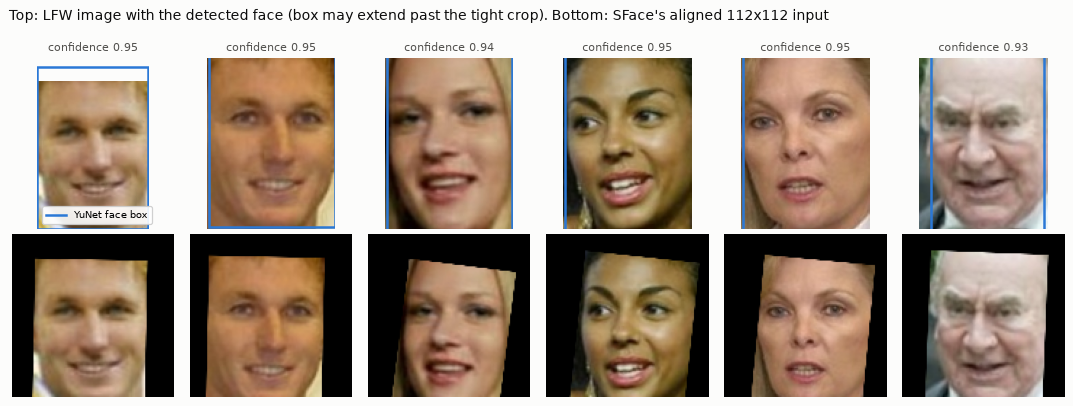

In [5]:
# What YuNet + SFace see: detected box and landmarks on 6 training images, and the aligned 112x112 faces.
fig, axes = plt.subplots(2, 6, figsize=(12, 4.6), dpi=90, facecolor=SURFACE)
for column, image in enumerate(flat[[0, 1, 2200, 2201, 3000, 3001] if len(flat) > 3001 else range(6)]):
    aligned, info = face.detect_and_align(image, detector, recognizer)
    axes[0, column].imshow(image)
    x, y, w, h = info["box"]
    axes[0, column].add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=BLUE, linewidth=2))
    axes[0, column].set_title(f"confidence {info['score']:.2f}", fontsize=9, color=INK_2)
    axes[1, column].imshow(cv2.cvtColor(aligned, cv2.COLOR_BGR2RGB))
    for row in range(2):
        axes[row, column].axis("off")
axes[0, 0].plot([], [], color=BLUE, linewidth=2, label="YuNet face box")
axes[0, 0].legend(loc="lower left", fontsize=8, framealpha=0.9)
fig.suptitle("Top: LFW image with the detected face (box may extend past the tight crop). Bottom: SFace's aligned "
             "112x112 input", x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout()
fig.savefig(REPORT_DIR / "face_sface_alignment.png", dpi=120, facecolor=SURFACE, bbox_inches="tight")
plt.show()

<!-- id: sface_aligned -->
**Alignment.** Top: the YuNet box on the original LFW crop. It reaches past the image edge because the crop cuts
off the forehead; that is why `detect_and_align` adds a black border before detecting. Bottom: the 112x112 face
SFace actually embeds, rotated so the eyes are level and scaled to a fixed size. The black areas are where the
tight LFW crop ends.

In [6]:
# Choose the threshold on the TRAIN pairs: highest true-accept rate with FAR <= 1 %.
train_scores = face.pair_scores(train_embeddings[0::2], train_embeddings[1::2])  # cosine similarity per pair
missing = np.isnan(train_scores)
print(f"train pairs without a face in one of the images: {missing.sum()} (left out of the threshold choice)")
sface_choice = evaluation.threshold_at_far(y_train[~missing], train_scores[~missing], MAX_FAR)
SFACE_THRESHOLD = sface_choice["threshold"]
train_report = evaluation.verification_report(y_train[~missing], train_scores[~missing], SFACE_THRESHOLD)
display(pd.Series(train_report).to_frame("SFace, LFW train pairs").round(4))
print(f"SFace threshold (FAR <= {MAX_FAR:.0%} on train): {SFACE_THRESHOLD:.4f} -> FAR {sface_choice['far']:.4f}, "
      f"TAR {sface_choice['tar']:.4f}. For reference, OpenCV's documented cosine threshold for SFace is 0.363.")

train pairs without a face in one of the images: 0 (left out of the threshold choice)


,"SFace, LFW train pairs"
roc_auc,0.9989
eer,0.0055
tar_at_far_1%,0.9945
tar_at_far_0.1%,0.9909
threshold,0.2597
accuracy,0.9923
far,0.0100
frr,0.0055
impostor pairs,1100.0000
genuine pairs,1100.0000


SFace threshold (FAR <= 1% on train): 0.2597 -> FAR 0.0100, TAR 0.9945. For reference, OpenCV's documented cosine threshold for SFace is 0.363.


<!-- id: sface_threshold -->
**SFace threshold, chosen on the training pairs.**
- Ranking on the 2,200 training pairs: ROC-AUC 0.9989, equal error rate 0.55 %.
- The highest true-accept rate with FAR <= 1 % comes at a cosine similarity of **0.2597**: exactly 11 of the 1,100
  different-people pairs are accepted (FAR 1.00 %), and 99.45 % of the same-person pairs.
- OpenCV's sample code uses 0.363 for SFace. Ours is lower because it follows our stated rule (FAR <= 1 % on our
  training pairs).

## 3 · Showcase: a Siamese network trained on LFW

In [7]:
# Hold out 15 % of the training pairs for validation, by PERSON: nobody appears on both sides.
held = face.identity_disjoint_split(train_names, holdout=SIAMESE["holdout"], seed=config.SEED)
fit_idx, val_idx = np.flatnonzero(~held), np.flatnonzero(held)
fit_people = set(train_names.loc[fit_idx, "name_a"]) | set(train_names.loc[fit_idx, "name_b"])
val_people = set(train_names.loc[val_idx, "name_a"]) | set(train_names.loc[val_idx, "name_b"])
assert not fit_people & val_people
display(pd.DataFrame({"pairs": [len(fit_idx), len(val_idx)],
                      "same person": [int(y_train[fit_idx].sum()), int(y_train[val_idx].sum())],
                      "different people": [int((y_train[fit_idx] == 0).sum()), int((y_train[val_idx] == 0).sum())],
                      "people": [len(fit_people), len(val_people)]}, index=["training", "validation (held out)"]))

,pairs,same person,different people,people
training,1868,933,935,1806
validation (held out),332,167,165,326


<!-- id: split -->
**Held-out validation pairs for the Siamese network.** 15 % of the training pairs are held out *by person*: people
who share a pair are linked, and whole linked groups go to one side, so nobody appears in both. The result is
1,868 training pairs (1,806 people) and 332 validation pairs (326 people), balanced 167 same / 165 different.
Without this split, the network could recognise people it had trained on and validation would look too good.

I0000 00:00:1794887554.695570 37181664 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1794887554.695585 37181664 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Siamese network: 2,438,465 parameters, 180,481 trainable (MobileNetV2 frozen; trainable BatchNormalization layers: 0)


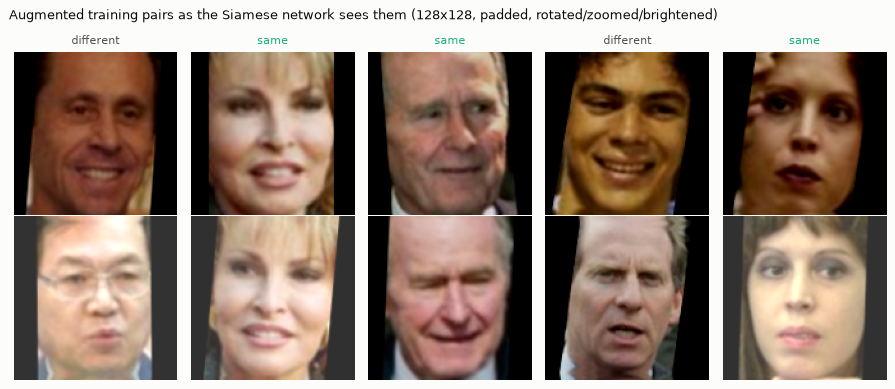

batch (32, 128, 128, 3) x 2, pixel range 0-255


In [8]:
siamese, embedding_model, backbone = face.build_siamese(SIAMESE["image_size"], SIAMESE["embedding_dim"],
                                                        SIAMESE["dropout"])
siamese.compile(optimizer=keras.optimizers.Adam(SIAMESE["learning_rate"], clipnorm=1.0),
                loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="roc_auc")])
trainable = int(sum(np.prod(w.shape) for w in siamese.trainable_weights))
n_bn_trainable = sum(l.trainable for l in backbone.layers if isinstance(l, keras.layers.BatchNormalization))
print(f"Siamese network: {siamese.count_params():,} parameters, {trainable:,} trainable (MobileNetV2 frozen; "
      f"trainable BatchNormalization layers: {n_bn_trainable})")
fit_ds = face.make_pair_dataset(train_pairs[fit_idx], y_train[fit_idx], SIAMESE["image_size"], SIAMESE["batch_size"],
                                training=True)
val_ds = face.make_pair_dataset(train_pairs[val_idx], y_train[val_idx], SIAMESE["image_size"], SIAMESE["batch_size"])

# one augmented training batch: the first 5 pairs
(face_a, face_b), labels = next(iter(fit_ds))
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4), dpi=90, facecolor=SURFACE)
for column in range(5):
    for row, batch in enumerate((face_a, face_b)):
        axes[row, column].imshow(batch[column].numpy().astype("uint8"))
        axes[row, column].axis("off")
    axes[0, column].set_title("same" if labels[column] == 1 else "different", fontsize=9,
                              color=SAME if labels[column] == 1 else INK_2)
fig.suptitle("Augmented training pairs as the Siamese network sees them (128x128, padded, rotated/zoomed/brightened)",
             x=0.01, ha="left", color=INK, fontsize=10)
fig.tight_layout()
plt.show()
print(f"batch {tuple(face_a.shape)} x 2, pixel range {float(tf.reduce_min(face_a)):.0f}-{float(tf.reduce_max(face_a)):.0f}")

<!-- id: siamese_model -->
**The Siamese network.**
- One embedding network processes both faces: frozen MobileNetV2 (ImageNet), then a trained Dense layer to 128
  numbers of length 1.
- The head compares the two embeddings (|a - b| and a x b, so the order of the faces does not matter) and outputs
  P(same person).
- Size: 2.44 M parameters, of which only 180,481 train (the head); no BatchNormalization layer trains.
- The example batch shows the input: faces padded to 128x128 (not stretched), with small random rotations, zooms
  and brightness changes, each face separately.

In [9]:
SIAMESE_PATH = MODEL_DIR / "face_siamese.keras"
callbacks = models.training_callbacks(SIAMESE_PATH, REPORT_DIR / "face_siamese_log.csv", SIAMESE["patience"],
                                      "val_roc_auc", "max", SIAMESE["reduce_lr_patience"])
history = siamese.fit(fit_ds, validation_data=val_ds, epochs=SIAMESE["max_epochs"], callbacks=callbacks, verbose=2)
epoch_seconds = callbacks[-1].seconds
siamese_log = pd.read_csv(REPORT_DIR / "face_siamese_log.csv")
print(f"\n{len(siamese_log)} epochs, {np.mean(epoch_seconds):.0f} s per epoch; best val ROC-AUC "
      f"{siamese_log['val_roc_auc'].max():.4f} (epoch {siamese_log['val_roc_auc'].idxmax() + 1}); "
      f"best model saved to {SIAMESE_PATH.relative_to(ROOT) if SIAMESE_PATH.is_relative_to(ROOT) else SIAMESE_PATH}")

Epoch 1/40


/Users/abhishekchandra/Developer/ekyc-verification/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


59/59 - 13s - 224ms/step - loss: 0.6913 - roc_auc: 0.5395 - val_loss: 0.6792 - val_roc_auc: 0.6974 - learning_rate: 0.0010


Epoch 2/40


59/59 - 6s - 108ms/step - loss: 0.6636 - roc_auc: 0.6780 - val_loss: 0.6325 - val_roc_auc: 0.7456 - learning_rate: 0.0010


Epoch 3/40


... (21 outputs left out)

59/59 - 6s - 108ms/step - loss: 0.3673 - roc_auc: 0.9216 - val_loss: 0.5960 - val_roc_auc: 0.7668 - learning_rate: 2.5000e-04


Epoch 12: early stopping


Restoring model weights from the end of the best epoch: 6.



12 epochs, 7 s per epoch; best val ROC-AUC 0.7768 (epoch 6); best model saved to models/face_siamese.keras


<!-- id: siamese_training -->
**Training.**
- Each epoch takes about 7 s (59 batches).
- The best validation ROC-AUC was **0.777, at epoch 6**. The learning rate was halved three times (after epochs
  8, 10 and 12) without improvement, and early stopping ended training at epoch 12 with the epoch-6 weights
  restored.
- The best model is saved as `models/face_siamese.keras`.

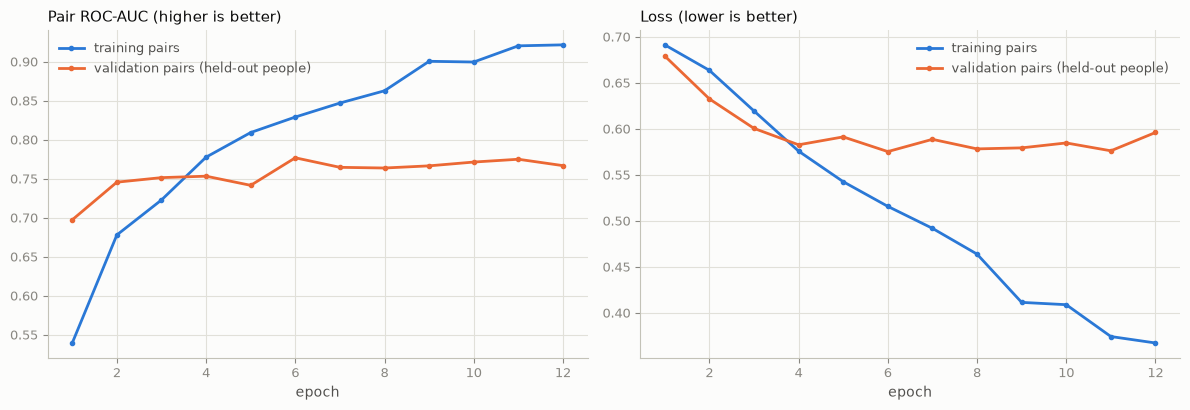

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), dpi=100, facecolor=SURFACE)
epochs = np.arange(1, len(siamese_log) + 1)
for ax, (train_col, val_col, title) in zip(axes, [("roc_auc", "val_roc_auc", "Pair ROC-AUC (higher is better)"),
                                                  ("loss", "val_loss", "Loss (lower is better)")]):
    ax.plot(epochs, siamese_log[train_col], color=BLUE, linewidth=2, marker="o", markersize=3, label="training pairs")
    ax.plot(epochs, siamese_log[val_col], color=ORANGE, linewidth=2, marker="o", markersize=3,
            label="validation pairs (held-out people)")
    style(ax, title)
    ax.set_xlabel("epoch")
    ax.legend(frameon=False, labelcolor=INK_2, fontsize=9)
fig.tight_layout()
fig.savefig(REPORT_DIR / "face_siamese_training_curves.png", dpi=150, facecolor=SURFACE)
plt.show()

<!-- id: siamese_curves -->
**Training curves: clear overfitting.** Training ROC-AUC keeps climbing (0.54 to 0.92) while validation stays
around 0.75-0.78 after epoch 2, and the validation loss stops falling after epoch 4. The head memorises the
training people; what it learned does not carry over to new people. The reason: ImageNet features describe
objects and textures, not the small differences between individual faces, and 1,868 pairs are far too few to
learn those from.

In [11]:
siamese = keras.models.load_model(SIAMESE_PATH)  # the best epoch, exactly as saved
val_scores = siamese.predict(val_ds, verbose=0)[:, 0]
siamese_choice = evaluation.threshold_at_far(y_train[val_idx], val_scores, MAX_FAR)
SIAMESE_THRESHOLD = siamese_choice["threshold"]
val_report = evaluation.verification_report(y_train[val_idx], val_scores, SIAMESE_THRESHOLD)
display(pd.Series(val_report).to_frame("Siamese, held-out validation pairs").round(4))
print(f"Siamese threshold (FAR <= {MAX_FAR:.0%} on validation): {SIAMESE_THRESHOLD:.4f} -> FAR "
      f"{siamese_choice['far']:.4f}, TAR {siamese_choice['tar']:.4f}; with {int((y_train[val_idx] == 0).sum())} "
      f"different-people pairs, 1 % FAR allows {int(MAX_FAR * (y_train[val_idx] == 0).sum())} false accept(s)")

,"Siamese, held-out validation pairs"
roc_auc,0.7767
eer,0.2801
tar_at_far_1%,0.0359
tar_at_far_0.1%,0.0299
threshold,0.8191
accuracy,0.5120
far,0.0061
frr,0.9641
impostor pairs,165.0000
genuine pairs,167.0000


Siamese threshold (FAR <= 1% on validation): 0.8191 -> FAR 0.0061, TAR 0.0359; with 165 different-people pairs, 1 % FAR allows 1 false accept(s)


<!-- id: siamese_threshold -->
**Siamese threshold, chosen on the held-out pairs.** Validation ROC-AUC 0.777, equal error rate 28 %. To keep FAR
<= 1 % (with 165 different-people pairs that means at most 1 false accept), the threshold must be 0.819, and
there only 3.6 % of same-person pairs are accepted. At the strict operating point KYC needs, this network
accepts almost nobody.

## 4 · LFW test pairs: one evaluation of both models

Both thresholds are fixed above (SFace on train pairs, the Siamese network on its validation pairs). The 1,000
test pairs (963 people, none of them in the training pairs) are scored once, and nothing is changed afterwards.

In [12]:
start = time.perf_counter()
test_flat = test_pairs.reshape(-1, *test_pairs.shape[2:])
test_embeddings, test_detect = face.embed_images(test_flat, detector, recognizer)
sface_test = face.pair_scores(test_embeddings[0::2], test_embeddings[1::2])
test_missing = np.isnan(sface_test)
# A pair whose face was not found cannot be accepted: score it -1 (lowest possible cosine) = rejected.
sface_test = np.where(test_missing, -1.0, sface_test)
siamese_test = siamese.predict(face.make_pair_dataset(test_pairs, y_test, SIAMESE["image_size"], 64), verbose=0)[:, 0]
print(f"scored {len(y_test)} test pairs in {time.perf_counter() - start:.0f} s; images without a found face: "
      f"{(~test_detect['found']).sum()} of {len(test_flat)} (pairs affected: {test_missing.sum()}, counted as rejected)")

test_scores = {"SFace (production)": sface_test, "Siamese (showcase)": siamese_test}
thresholds = {"SFace (production)": SFACE_THRESHOLD, "Siamese (showcase)": SIAMESE_THRESHOLD}
test_report = pd.DataFrame({m: evaluation.verification_report(y_test, s, thresholds[m]) for m, s in test_scores.items()})
display(test_report.round(4))
test_report.to_csv(REPORT_DIR / "face_lfw_test_metrics.csv")
print(f"FAR 0.1 % of {int((y_test == 0).sum())} different-people pairs = {0.001 * (y_test == 0).sum():.1f} pairs, so "
      f"'TAR at FAR 0.1 %' here means TAR with no false accept at all")

scored 1000 test pairs in 20 s; images without a found face: 0 of 2000 (pairs affected: 0, counted as rejected)


,SFace (production),Siamese (showcase)
roc_auc,0.9968,0.7788
eer,0.0160,0.3000
tar_at_far_1%,0.9840,0.1040
tar_at_far_0.1%,0.9760,0.0100
threshold,0.2597,0.8191
accuracy,0.9820,0.5230
far,0.0220,0.0040
frr,0.0140,0.9500
impostor pairs,500.0000,500.0000
genuine pairs,500.0000,500.0000


FAR 0.1 % of 500 different-people pairs = 0.5 pairs, so 'TAR at FAR 0.1 %' here means TAR with no false accept at all


<!-- id: test_metrics -->
**LFW test: the one evaluation (1,000 pairs of new people, thresholds fixed beforehand).**

| | SFace (production) | Siamese (showcase) |
|---|---|---|
| ROC-AUC | **0.997** | 0.779 |
| equal error rate | 1.6 % | 30.0 % |
| TAR at FAR 1 % | 98.4 % | 10.4 % |
| TAR at FAR 0.1 % (no false accept) | 97.6 % | 1.0 % |
| at its threshold: accuracy | 98.2 % | 52.3 % |
| at its threshold: FAR / FRR | **2.2 %** / 1.4 % | 0.4 % / 95.0 % |

YuNet found a face in all 2,000 test images.

- **SFace** separates the pairs almost perfectly, but its threshold accepted **11 of 500 impostor pairs (2.2 %)**,
  more than the 1 % target. The Wilson 95 % interval for 11/500 is about 1.2-3.9 %, so the excess is real, not
  chance. On the training pairs the threshold sat exactly on the 1 % boundary, and new people pushed FAR over it.
  The threshold is not changed after seeing the test set; Phase 7 must handle this (see the summary).
- **The Siamese network** is far weaker: its strict threshold rejects 95 % of genuine pairs. It is a teaching
  example of why production systems use a recognizer trained on millions of face images.

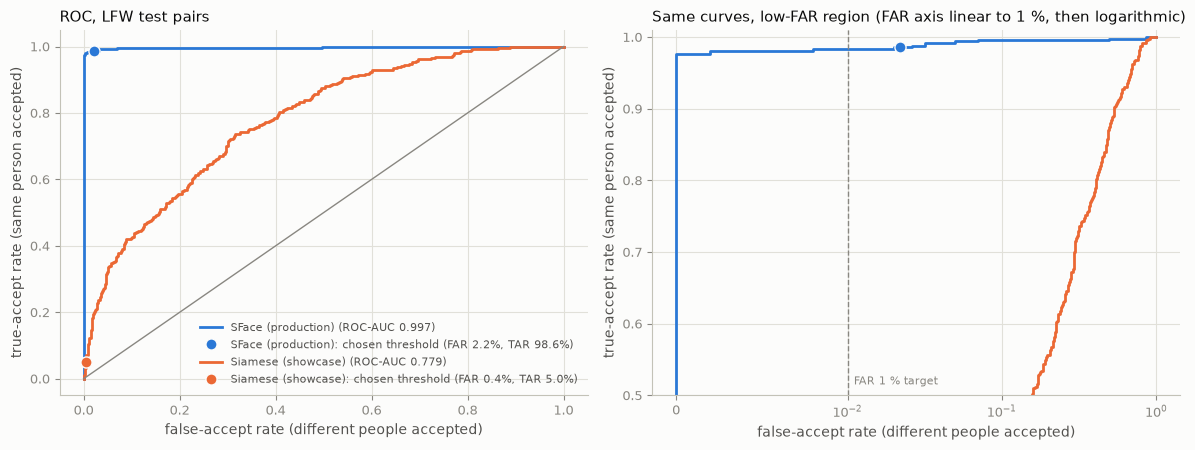

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), dpi=100, facecolor=SURFACE)
for name, s in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    r = test_report[name]
    for ax in axes:
        ax.plot(fpr, tpr, color=MODEL_COLOR[name], linewidth=2, label=f"{name} (ROC-AUC {r['roc_auc']:.3f})")
        ax.plot(r["far"], 1 - r["frr"], "o", color=MODEL_COLOR[name], markersize=8, markeredgecolor=SURFACE,
                label=f"{name}: chosen threshold (FAR {r['far']:.1%}, TAR {1 - r['frr']:.1%})")
axes[1].set_xscale("symlog", linthresh=0.01)
axes[1].axvline(MAX_FAR, color=MUTED, linewidth=1, linestyle="--")
axes[1].text(MAX_FAR * 1.1, 0.03, "FAR 1 % target", color=MUTED, fontsize=8, transform=axes[1].get_xaxis_transform())
axes[0].plot([0, 1], [0, 1], color=MUTED, linewidth=1)
style(axes[0], "ROC, LFW test pairs")
style(axes[1], "Same curves, low-FAR region (FAR axis linear to 1 %, then logarithmic)")
for ax in axes:
    ax.set(xlabel="false-accept rate (different people accepted)", ylabel="true-accept rate (same person accepted)")
axes[0].legend(frameon=False, labelcolor=INK_2, fontsize=8, loc="lower right")
axes[1].set_ylim(0.5, 1.01)
fig.tight_layout()
fig.savefig(REPORT_DIR / "face_lfw_roc_test.png", dpi=150, facecolor=SURFACE, bbox_inches="tight")
plt.show()

<!-- id: test_roc -->
**ROC curves on the test pairs.** Left: SFace (blue) hugs the top-left corner; the Siamese network (orange) lies
far below it. Right: the low-FAR region, linear up to 1 % and logarithmic after. SFace still accepts 97.6 % of
same-person pairs at FAR 0, and its chosen threshold (dot) lies just right of the 1 % line. The Siamese
network's dot sits near the bottom: few false accepts, but almost no true accepts either.

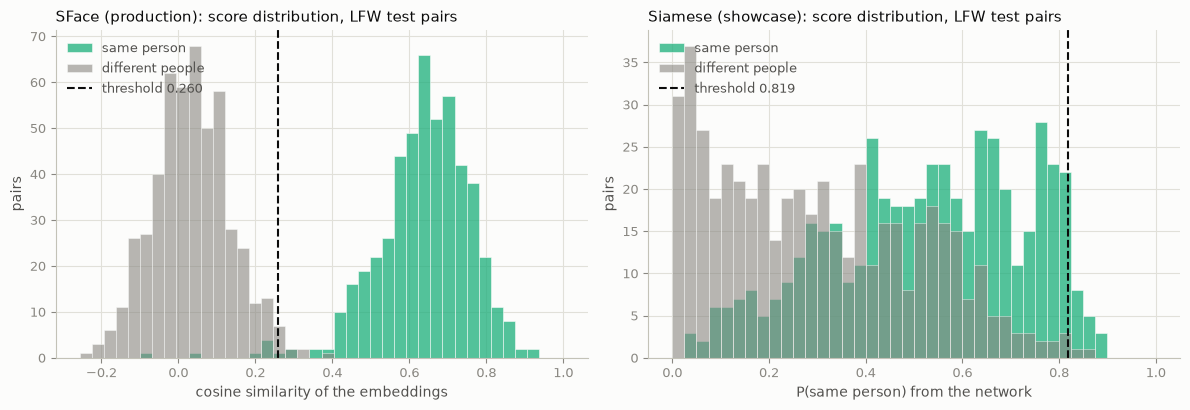

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), dpi=100, facecolor=SURFACE)
for ax, (name, s), xlabel in zip(axes, test_scores.items(),
                                 ("cosine similarity of the embeddings", "P(same person) from the network")):
    bins = np.linspace(min(s.min(), 0), 1, 41)
    ax.hist(s[y_test == 1], bins=bins, color=SAME, alpha=0.75, label="same person", edgecolor=SURFACE, linewidth=0.5)
    ax.hist(s[y_test == 0], bins=bins, color=DIFFERENT, alpha=0.6, label="different people", edgecolor=SURFACE,
            linewidth=0.5)
    ax.axvline(thresholds[name], color=INK, linewidth=1.5, linestyle="--", label=f"threshold {thresholds[name]:.3f}")
    style(ax, f"{name}: score distribution, LFW test pairs")
    ax.set(xlabel=xlabel, ylabel="pairs")
    ax.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(REPORT_DIR / "face_score_hist_test.png", dpi=150, facecolor=SURFACE, bbox_inches="tight")
plt.show()

<!-- id: test_hist -->
**Score distributions on the test pairs.** SFace (left): different people centre near 0 (unrelated embeddings)
and same-person pairs near 0.65, with only a thin overlap around 0.2-0.35, where the threshold (0.260) sits. The
Siamese network (right): the two distributions overlap almost everywhere. No threshold separates them, so a
strict threshold (0.819) has to reject nearly everyone.

SFace on LFW test: 11 false accepts, 7 false rejects


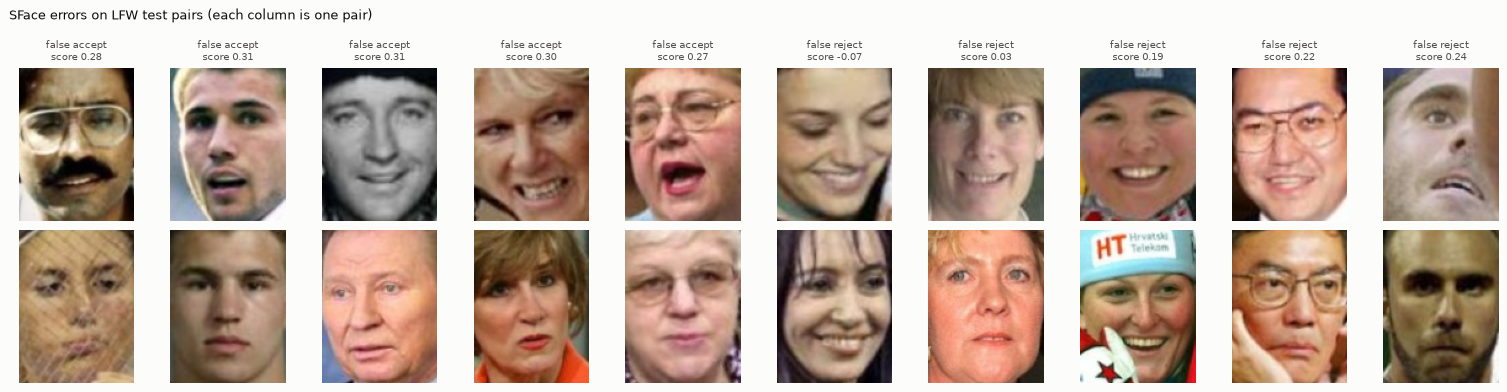

In [15]:
# SFace's mistakes at its threshold: every false accept and up to 5 false rejects (lowest-scoring same pairs).
accepted = sface_test >= SFACE_THRESHOLD
false_accepts = np.flatnonzero(accepted & (y_test == 0))
false_rejects = np.flatnonzero(~accepted & (y_test == 1))
show = list(false_accepts[:5]) + list(false_rejects[np.argsort(sface_test[false_rejects])][:5])
print(f"SFace on LFW test: {len(false_accepts)} false accepts, {len(false_rejects)} false rejects")
if show:
    fig, axes = plt.subplots(2, len(show), figsize=(1.6 * len(show) + 1, 4.4), dpi=90, facecolor=SURFACE, squeeze=False)
    for column, i in enumerate(show):
        for row in range(2):
            axes[row, column].imshow(test_pairs[i, row])
            axes[row, column].axis("off")
        kind = "false accept" if y_test[i] == 0 else "false reject"
        axes[0, column].set_title(f"{kind}\nscore {sface_test[i]:.2f}", fontsize=8, color=INK_2)
    fig.suptitle("SFace errors on LFW test pairs (each column is one pair)", x=0.01, ha="left", color=INK, fontsize=10)
    fig.tight_layout()
    fig.savefig(REPORT_DIR / "face_sface_errors_test.png", dpi=120, facecolor=SURFACE, bbox_inches="tight")
    plt.show()

<!-- id: test_errors -->
**SFace's mistakes on the test pairs: 11 false accepts, 7 false rejects.**
- The five false accepts shown score 0.27-0.31, just above the threshold. They are look-alikes: same sex, age,
  glasses or moustache, similar pose.
- The false rejects show what breaks a match: the head tilted up or down, hats and headgear, and large changes
  in age or appearance between the two photos.
- For KYC: ask for a frontal, uncovered selfie, and send scores near the threshold to manual review.

## 5 · Sanity check on ID photos (synthetic, not a benchmark)

There are no real selfie-ID pairs in this project. As a sanity check of the production model on ID-card photos:
- the face is cut from each **genuine template** with the annotated `photo` box;
- **match pair** = that ID face against an altered copy of itself standing in for a selfie: rotation, scale,
  brightness, blur and a JPEG save;
- **non-match pair** = the faces of two different documents.

The SFace threshold from LFW is applied unchanged. A copy of the same photo is far easier than a real selfie
(same pose, expression and lighting), so the match side is optimistic. The useful outputs are the detector's
behaviour on ID photos and the non-match scores.

In [16]:
manifest = pd.read_csv(config.MANIFEST_CSV)
ids = manifest[(manifest["source"] == "template") & (manifest["label"] == 0)].sort_values("doc_id").reset_index(drop=True)
if N_ID_DOCS:
    ids = ids.groupby("doc_type").head(max(1, N_ID_DOCS // 10)).reset_index(drop=True)
photo_boxes = pd.read_csv(config.FIELDS_GT_CSV).query("field_name == 'photo'").set_index("doc_id")[["x", "y", "w", "h"]]
id_faces, id_rows = [], []
for row in ids.itertuples():
    with Image.open(ROOT / row.image_path) as image:  # original template (read-only); CMYK files become RGB
        page = np.asarray(image.convert("RGB"))
    crop = face.crop_with_margin(page, photo_boxes.loc[row.doc_id].to_numpy(), margin=0.15)
    aligned, info = face.detect_and_align(crop, detector, recognizer)
    id_faces.append(crop)
    # grey photo: the aligned FACE has (almost) no colour (the card background around it often does)
    grey = aligned is not None and np.abs(aligned.astype(float) - aligned.mean(axis=2, keepdims=True)).mean() < 4
    id_rows.append({"doc_id": row.doc_id, "doc_type": row.doc_type, "crop_w": crop.shape[1], "crop_h": crop.shape[0],
                    "found": aligned is not None, "faces": info["faces"], "score": info["score"], "grey": bool(grey)})
id_table = pd.DataFrame(id_rows)
id_embeddings, _ = face.embed_images(id_faces, detector, recognizer)
per_type = id_table.groupby("doc_type").agg(documents=("found", "size"), face_found=("found", "mean"),
                                            median_confidence=("score", "median"), grey_photo=("grey", "mean"),
                                            crop_width_px=("crop_w", "median"))
display(per_type.round(3))
print(f"faces found on {id_table['found'].sum()} of {len(id_table)} ID photos; more than one face in "
      f"{(id_table['faces'] > 1).sum()} crops")
if (~id_table["found"]).any():
    print("no face found:", ", ".join(id_table.loc[~id_table["found"], "doc_id"]))

,documents,face_found,median_confidence,grey_photo,crop_width_px
doc_type,,,,,
alb_id,100,1.00,0.929,1.00,556.0
aze_passport,100,1.00,0.928,1.00,586.0
esp_id,100,1.00,0.944,0.94,440.0
est_id,100,0.99,0.947,0.99,353.0
fin_id,100,1.00,0.942,0.45,304.0
grc_passport,100,1.00,0.953,0.00,385.0
lva_passport,100,1.00,0.915,1.00,699.0
rus_internalpassport,100,1.00,0.948,0.10,514.0
srb_passport,100,1.00,0.910,1.00,705.0


faces found on 999 of 1000 ID photos; more than one face in 0 crops
no face found: est_id_64


<!-- id: id_detect -->
**Detection on ID-card photos** (the `photo` box of all 1,000 genuine templates, with a 15 % margin):
- YuNet found a face on **999 of 1,000**, with median confidence 0.91-0.95 per type.
- **The one miss is est_id_64:** a very dark, low-contrast portrait (a dark-skinned face printed almost black in
  greyscale). Dark or low-contrast ID photos are exactly where face pipelines fail first, and this is a fairness
  risk to monitor with real data.
- Most photos are greyscale (all of alb_id, aze_passport, lva_passport and srb_passport; none on grc_passport).
- Photo crops are 300-700 px wide, so the faces are large enough.

In [17]:
# Match pairs: each ID face against a simulated selfie of it. Non-match pairs: two different documents' faces.
rng = np.random.default_rng(config.SEED)
selfies, selfie_params = zip(*(face.simulate_selfie(crop, rng) for crop in id_faces))
selfie_embeddings, selfie_detect = face.embed_images(selfies, detector, recognizer)
match_scores = face.pair_scores(id_embeddings, selfie_embeddings)
n = len(id_faces)
a = rng.integers(0, n, 3 * n)
b = (a + rng.integers(1, n, 3 * n)) % n  # always a different document
keep = np.unique(np.sort(np.c_[a, b], axis=1), axis=0)[:n]  # n distinct non-match pairs
nonmatch_scores = face.pair_scores(id_embeddings[keep[:, 0]], id_embeddings[keep[:, 1]])

id_pairs = pd.concat([
    pd.DataFrame({"kind": "match (ID vs simulated selfie)", "doc_a": id_table["doc_id"], "doc_b": id_table["doc_id"],
                  "doc_type": id_table["doc_type"], "score": match_scores}),
    pd.DataFrame({"kind": "non-match (two documents)", "doc_a": id_table["doc_id"].to_numpy()[keep[:, 0]],
                  "doc_b": id_table["doc_id"].to_numpy()[keep[:, 1]],
                  "doc_type": id_table["doc_type"].to_numpy()[keep[:, 0]], "score": nonmatch_scores}),
], ignore_index=True)
id_pairs["face missing"] = id_pairs["score"].isna()
id_pairs["accepted"] = id_pairs["score"] >= SFACE_THRESHOLD  # a missing face is never accepted
id_pairs.to_csv(REPORT_DIR / "face_id_sanity_pairs.csv", index=False)
summary = id_pairs.groupby("kind").agg(pairs=("score", "size"), face_missing=("face missing", "sum"),
                                       median_score=("score", "median"), lowest=("score", "min"), highest=("score", "max"),
                                       accepted=("accepted", "mean"))
display(summary.round(3))
match = id_pairs[id_pairs["kind"].str.startswith("match")]
nonmatch = id_pairs[id_pairs["kind"].str.startswith("non")]
print(f"at the LFW threshold {SFACE_THRESHOLD:.3f}: false rejects {int((~match['accepted']).sum())} of {len(match)} "
      f"match pairs ({(~match['accepted']).mean():.1%}, missing faces included); false accepts "
      f"{int(nonmatch['accepted'].sum())} of {len(nonmatch)} non-match pairs ({nonmatch['accepted'].mean():.2%})")
display(match.groupby("doc_type").agg(match_pairs=("score", "size"), false_reject=("accepted", lambda s: 1 - s.mean()),
                                      median_score=("score", "median")).round(3))
print("highest-scoring non-match pairs (possible re-used faces):")
display(nonmatch.nlargest(5, "score")[["doc_a", "doc_b", "score"]].round(3))

# Where do high non-match scores come from? Same card design, or two grey (black-and-white) photos?
grey = id_table.set_index("doc_id")["grey"]
doc_type_of = id_table.set_index("doc_id")["doc_type"]
nonmatch = nonmatch.assign(**{"same document type": (doc_type_of[nonmatch["doc_a"]].to_numpy() ==
                                                     doc_type_of[nonmatch["doc_b"]].to_numpy()),
                              "both faces grey": grey[nonmatch["doc_a"]].to_numpy() & grey[nonmatch["doc_b"]].to_numpy()})
display(nonmatch.groupby(["same document type", "both faces grey"])["score"].agg(
    pairs="size", median="median", false_accept_rate=lambda s: (s >= SFACE_THRESHOLD).mean()).round(3))
# Information only (synthetic data; nothing here is used or saved as a setting): the threshold that would keep
# FAR <= 1 % on these ID non-match pairs, and what it would cost on the match pairs.
both = id_pairs.dropna(subset=["score"])
id_choice = evaluation.threshold_at_far(both["kind"].str.startswith("match").astype(int), both["score"], MAX_FAR)
print(f"information only: FAR <= 1 % on these ID pairs would need a threshold of {id_choice['threshold']:.3f} "
      f"(LFW: {SFACE_THRESHOLD:.3f}); match pairs accepted there: {id_choice['tar']:.1%}")

,pairs,face_missing,median_score,lowest,highest,accepted
kind,,,,,,
match (ID vs simulated selfie),1000,1,0.927,0.362,0.983,0.999
non-match (two documents),1000,1,0.189,-0.149,0.937,0.299


at the LFW threshold 0.260: false rejects 1 of 1000 match pairs (0.1%, missing faces included); false accepts 299 of 1000 non-match pairs (29.90%)


,match_pairs,false_reject,median_score
doc_type,,,
alb_id,100,0.00,0.930
aze_passport,100,0.00,0.927
esp_id,100,0.00,0.931
est_id,100,0.01,0.903
fin_id,100,0.00,0.895
grc_passport,100,0.00,0.930
lva_passport,100,0.00,0.933
rus_internalpassport,100,0.00,0.923
srb_passport,100,0.00,0.941


highest-scoring non-match pairs (possible re-used faces):


,doc_a,doc_b,score
1866,aze_passport_63,est_id_60,0.937
1378,alb_id_73,esp_id_31,0.726
1325,alb_id_63,aze_passport_54,0.687
1044,alb_id_09,lva_passport_06,0.648
1586,aze_passport_09,srb_passport_25,0.635


pairs  median  false_accept_rate
same document type both faces grey                                  
False              False              331   0.197              0.311
                   True               611   0.186              0.298
True               True                58   0.186              0.241

information only: FAR <= 1 % on these ID pairs would need a threshold of 0.556 (LFW: 0.260); match pairs accepted there: 99.9%


<!-- id: id_scores -->
**Scores on ID photos at the LFW threshold (0.260).**
- **Match pairs** (ID photo against its simulated selfie): median 0.927, lowest 0.362. All 999 pairs with a
  detected face are accepted; the only false reject is est_id_64, whose face was not found. This side is easy:
  it is a copy of the same photo.
- **Non-match pairs** (two different documents): median 0.189, but **299 of 1,000 (29.9 %) are accepted**, 30 times
  the target FAR. It is not caused by the card design or greyscale photos: the false-accept rate is about the same
  (0.24-0.31) for same/different document type and grey/colour faces.
- **The highest non-match pair, aze_passport_63 vs est_id_60 (0.937), shows the same synthetic face** (checked by
  eye): the dataset reuses portraits across documents, so a few "non-match" pairs are really matches. The next one
  (alb_id_73 vs esp_id_31, 0.73) shows two different but very similar-looking generated faces.
- The likely cause is that the SIDTD portraits are generated faces in one uniform style (frontal, neutral
  expression, even lighting). To SFace they look far more alike than LFW's varied photos of real people.
- For information only, nothing is changed: FAR <= 1 % on these pairs would need a threshold of about 0.556.

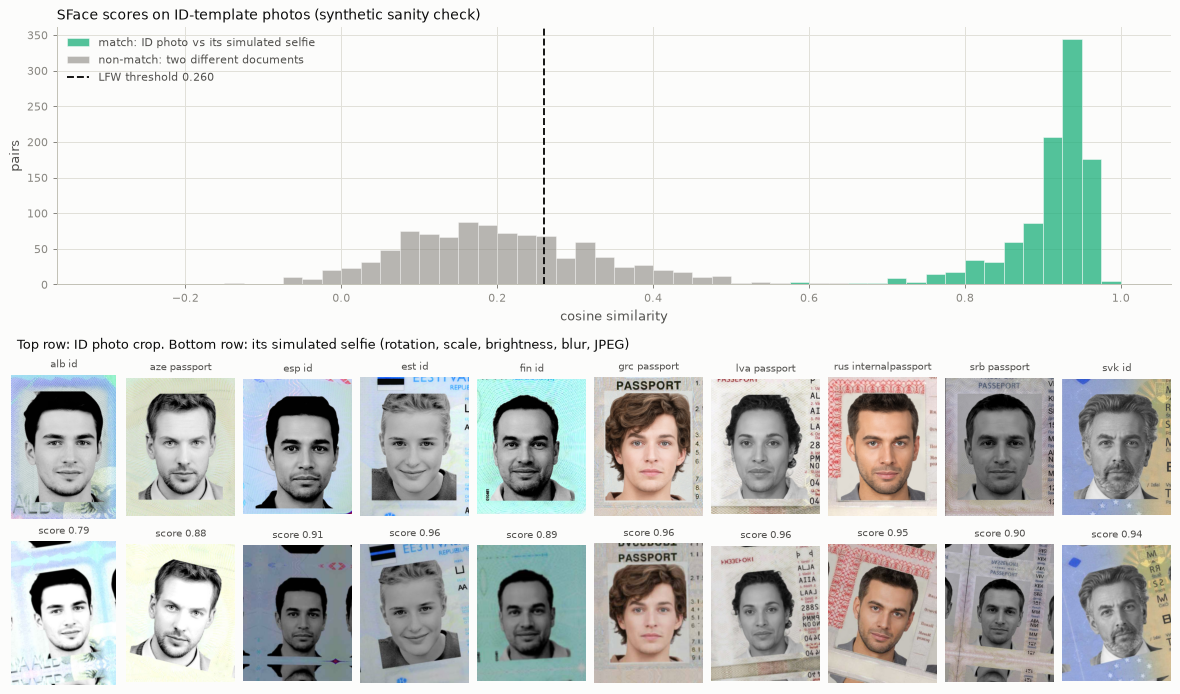

In [18]:
fig = plt.figure(figsize=(13, 7.6), dpi=90, facecolor=SURFACE, layout="constrained")
top, bottom = fig.subfigures(2, 1, height_ratios=[1, 1.1])
ax = top.subplots()
bins = np.linspace(-0.3, 1, 53)
ax.hist(match["score"].dropna(), bins=bins, color=SAME, alpha=0.75, label="match: ID photo vs its simulated selfie",
        edgecolor=SURFACE, linewidth=0.5)
ax.hist(nonmatch["score"].dropna(), bins=bins, color=DIFFERENT, alpha=0.6, label="non-match: two different documents",
        edgecolor=SURFACE, linewidth=0.5)
ax.axvline(SFACE_THRESHOLD, color=INK, linewidth=1.5, linestyle="--", label=f"LFW threshold {SFACE_THRESHOLD:.3f}")
style(ax, "SFace scores on ID-template photos (synthetic sanity check)")
ax.set(xlabel="cosine similarity", ylabel="pairs")
ax.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="upper left")
# one document per type: ID photo crop (top row) and its simulated selfie (bottom row)
axes = bottom.subplots(2, 10)
for column, (doc_type, rows) in enumerate(id_table.groupby("doc_type")):
    i = rows.index[0]
    for row, image in enumerate((id_faces[i], selfies[i])):
        axes[row, column].imshow(image)
        axes[row, column].axis("off")
    axes[0, column].set_title(doc_type.replace("_", " "), fontsize=8, color=INK_2)
    axes[1, column].set_title(f"score {match_scores[i]:.2f}" if not np.isnan(match_scores[i]) else "no face",
                              fontsize=8, color=INK_2)
bottom.suptitle("Top row: ID photo crop. Bottom row: its simulated selfie (rotation, scale, brightness, blur, JPEG)",
                x=0.01, ha="left", color=INK, fontsize=10)
fig.savefig(REPORT_DIR / "face_id_sanity.png", dpi=120, facecolor=SURFACE, bbox_inches="tight")
plt.show()

<!-- id: id_hist -->
**Figure.** Top: ID match scores (green) sit at 0.8-1.0, far from the threshold. The non-match scores (grey)
spread from 0 to 0.5, and a large share lies right of the LFW threshold: the LFW threshold is far too permissive
for this kind of image. Bottom: one document per type, its photo crop and the simulated selfie (rotated, scaled,
darker or brighter, blurred, JPEG-compressed). A real selfie differs much more (pose, expression, lighting,
camera, years between photos), so real match scores will be lower than here.

## 6 · Saving the configuration

In [19]:
face_config = {
    "production_method": "YuNet face detector + SFace face recognizer (OpenCV cv2.FaceDetectorYN / "
                         "cv2.FaceRecognizerSF); score = cosine similarity of the two SFace embeddings",
    "opencv_version": cv2.__version__,
    "models": {role: {"file": f"models/face/{r['file']}", "bytes": int(SOURCES[role][1].stat().st_size),
                      "sha256": r["sha256"], "license": r["license"], "source": r["source"]}
               for role, r in model_files.iterrows()},
    "detector_settings": face.DETECTOR_SETTINGS,
    "input": {"image": "RGB (uint8 0-255 or float 0-1), any size; converted to BGR inside ekyc.face",
              "aligned_face": [112, 112, 3], "embedding": "128 numbers, scaled to length 1"},
    "decision": {"rule": "same person if score >= threshold", "threshold": round(SFACE_THRESHOLD, 4),
                 "chosen_on": f"LFW development train pairs ({len(y_train)}): highest TAR with FAR <= {MAX_FAR:.0%}",
                 "train_far": round(sface_choice["far"], 4), "train_tar": round(sface_choice["tar"], 4)},
    "no_face_found": "no score: ask for a new photo or route to manual review (never accept)",
    "lfw_test": {k: round(v, 4) if isinstance(v, float) else v for k, v in test_report["SFace (production)"].items()},
    "siamese_showcase": {"file": "models/face_siamese.keras",
                         "input": f"two RGB faces, resized with padding to {SIAMESE['image_size']}x{SIAMESE['image_size']}, "
                                  "pixels 0-255 (the model rescales them)",
                         "output": "P(same person)", "threshold": round(SIAMESE_THRESHOLD, 4),
                         "chosen_on": f"{len(val_idx)} held-out LFW train pairs (people not used for training)",
                         "lfw_test": {k: round(v, 4) if isinstance(v, float) else v
                                      for k, v in test_report["Siamese (showcase)"].items()}},
    "scope": "threshold from LFW (celebrity photos); re-check on real selfie-ID pairs before production use",
}
(MODEL_DIR / "face_config.json").write_text(json.dumps(face_config, indent=2))
metrics = {"lfw": {"train_pairs": len(y_train), "test_pairs": len(y_test), "siamese_fit_pairs": len(fit_idx),
                   "siamese_val_pairs": len(val_idx)},
           "sface_train": train_report, "siamese_val": val_report, "lfw_test": test_report.to_dict(),
           "detection_rate": {"lfw_train": float(train_detect["found"].mean()), "lfw_test": float(test_detect["found"].mean()),
                              "id_photos": float(id_table["found"].mean())},
           "id_sanity": summary.to_dict(orient="index"),
           "siamese_epochs": len(siamese_log), "siamese_seconds_per_epoch": float(np.mean(epoch_seconds)),
           "peak_memory_gb": round(peak_memory_gb(), 2)}
(REPORT_DIR / "face_metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
print(json.dumps(face_config["decision"], indent=2))
print(f"peak memory {metrics['peak_memory_gb']} GB | swap now {swap_used_gb():.1f} GB | "
      f"notebook run time {(time.perf_counter() - notebook_start) / 60:.1f} min")
for path in [MODEL_DIR / "face_config.json", SIAMESE_PATH, *sorted(REPORT_DIR.glob("face_*"))]:
    print(f"  {path.relative_to(ROOT) if path.is_relative_to(ROOT) else path}")

{
  "rule": "same person if score >= threshold",
  "threshold": 0.2597,
  "chosen_on": "LFW development train pairs (2200): highest TAR with FAR <= 1%",
  "train_far": 0.01,
  "train_tar": 0.9945
}
peak memory 15.0 GB | swap now 20.7 GB | notebook run time 3.4 min
  models/face_config.json
  models/face_siamese.keras
  reports/phase4/face_id_sanity.png
  reports/phase4/face_id_sanity_pairs.csv
  reports/phase4/face_lfw_examples.png
  reports/phase4/face_lfw_roc_test.png
  reports/phase4/face_lfw_test_metrics.csv
  reports/phase4/face_metrics.json
  reports/phase4/face_score_hist_test.png
  reports/phase4/face_sface_alignment.png
  reports/phase4/face_sface_errors_test.png
  reports/phase4/face_siamese_log.csv
  reports/phase4/face_siamese_training_curves.png


<!-- id: saved -->
**Saved.**
- **`models/face_config.json`** holds:
  - the production method (YuNet + SFace) and OpenCV version;
  - both model files with size, SHA-256, licence and source;
  - the detector settings and the input sizes (any RGB image -> aligned 112x112 face -> 128-number embedding);
  - the decision rule: same person if cosine >= **0.2597**, chosen on LFW train pairs for FAR <= 1 %;
  - the "no face found" policy (never accept: ask for a new photo or route to review);
  - the LFW test metrics, and the Siamese showcase's threshold and metrics.
- **`models/face_siamese.keras`** is the Siamese network.
- **`reports/phase4/`** holds the figures, CSVs and `face_metrics.json`.

The notebook ran for 3.4 min, peak memory 15.0 GB.

**For Phases 6-7:** LFW is a benchmark of celebrity photos, and the ID check shows its threshold does not carry
over to ID-card portraits. Before production, the threshold must be re-checked on real selfie-ID pairs. Until
then, scores near the threshold should go to manual review.